# Clasificación Molecular Automatizada de Gliomas mediante Machine Learning

## 1. Contexto del Problema y Justificación Oncológica
Los gliomas constituyen el grupo más común de tumores malignos primarios del sistema nervioso central. Clínicamente, se subdividen en dos categorías principales con prognósticos radicalmente distintos: **Gliomas de Bajo Grado (LGG)** y **Glioblastomas Multiformes (GBM)**. Mientras que los pacientes con LGG muestran tasas de supervivencia significativamente más altas, el GBM es una de las neoplasias más agresivas y letales del cuerpo humano.

Tradicionalmente, la gradación tumoral dependía exclusivamente del análisis histopatológico por biopsia invasiva. No obstante, la oncología moderna ha demostrado que el perfil genómico (las mutaciones somáticas del ADN tumoral) posee un poder predictivo muy superior. El reto radica en que secuenciar genomas completos de manera continua es costoso y computacionalmente denso. Este proyecto implementa un pipeline automatizado de inteligencia artificial para diagnosticar la gradación del tumor basándose de forma estricta en la presencia o ausencia de mutaciones específicas en genes clave identificados por proyectos de envergadura internacional como *The Cancer Genome Atlas (TCGA)*.

## 2. Enfoque de la Metodología y Selección de Modelos
Acorde a la naturaleza tabular y altamente dispersa de las características binarias de entrada (presencia/ausencia de mutación codificada como `0` o `1`), la estrategia metodológica adopta un marco comparativo entre enfoques paramétricos, modelos geométricos basados en fronteras de decisión y algoritmos basados en ensambles de árboles de decisión:

1. **Regresión Logística (Baseline):** Utilizada como modelo base lineal parametrizado para estimar las probabilidades de gradación tumoral mediante la función logística estándar.
2. **Máquinas de Vectores de Soporte (SVM):** Configurada con un kernel de Función de Base Radial (RBF) no lineal. El modelo busca mapear las características mutacionales a un espacio de mayor dimensionalidad para trazar un hiperplano de separación óptimo, controlando el compromiso de margen mediante el hiperparámetro de regularización $C$.
3. **Random Forest (Ensamble por Bagging):** Modelo no paramétrico estructurado para inducir un bosque de árboles de decisión independientes entrenados en subconjuntos paralelos de datos (*Bootstrap Aggregation*). Es el algoritmo de elección debido a su inmunidad natural ante el sobreajuste (*overfitting*) en datos tabulares genómicos y su capacidad nativa de calcular la importancia de características.

## 3. Hoja de Ruta del Pipeline de Machine Learning
El desarrollo del experimento sigue estrictamente las siguientes fases secuenciales implementadas en el código:
* **Fase I: Carga y Curación del Dataset:** Importación de registros tabulares clínicos del repositorio de la UCI (`Glioma Grading Clinical and Mutation Features`).
* **Fase II: Preprocesamiento Estricto:** Codificación categórica mediante *One-Hot Encoding* para características demográficas (v.g., raza) y escalamiento de variables continuas utilizando `StandardScaler` para garantizar la convergencia óptima del gradiente en SVM y Regresión Logística.
* **Fase III: División Estratificada de Datos:** Fragmentación de los conjuntos de entrenamiento (80%) y prueba (20%) empleando `train_test_split` con el parámetro `stratify` para preservar la distribución nativa de las clases tumorales en ambos bloques.
* **Fase IV: Entrenamiento de Modelos:** Ajuste paralelo de los clasificadores seleccionados mediante estructuras de diccionario en Python.
* **Fase V: Validación Cruzada:** Evaluación robusta a través de *Stratified K-Fold Cross-Validation* ($k=10$) para mitigar la varianza estadística del error de prueba.
* **Fase VI: Análisis de Importancia de Variables:** Extracción y ordenamiento de coeficientes y pesos genéticos para aislar los biomarcadores con mayor relevancia clínica.

In [ ]:
# libreriasas principales

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:

# 2. carga del dataset UCI


!pip install ucimlrepo -q

from ucimlrepo import fetch_ucirepo

glioma = fetch_ucirepo(id=759)

X = glioma.data.features
y = glioma.data.targets

df = pd.concat([X, y], axis=1)

print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (839, 24)


,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,...,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade
0,0,51.30,white,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,38.72,white,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,0,35.17,white,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,32.78,white,1,1,1,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,0,31.51,white,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
print(df.columns)

Index(['Gender', 'Age_at_diagnosis', 'Race', 'IDH1', 'TP53', 'ATRX', 'PTEN',
       'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1',
       'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4',
       'PDGFRA', 'Grade'],
      dtype='object')


In [ ]:
df['Grade'].value_counts()

,count
Grade,
0,487
1,352


Grade
0    487
1    352
Name: count, dtype: int64


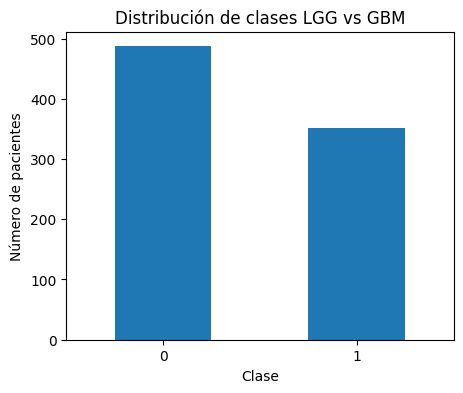

In [ ]:
# Distribución de clases
class_counts = df['Grade'].value_counts().sort_index()
print(class_counts)

plt.figure(figsize=(5,4))
class_counts.plot(kind='bar')
plt.title("Distribución de clases LGG vs GBM")
plt.xlabel("Clase")
plt.ylabel("Número de pacientes")
plt.xticks(rotation=0)
plt.show()


El dataset presenta una distribución relativamente balanceada entre las clases LGG y GBM, aunque existe una mayor cantidad de casos LGG. Esta diferencia no es extrema, pero justifica el uso de división estratificada para mantener proporciones similares en entrenamiento y prueba.

In [ ]:
df.isnull().sum()

,0
Gender,0
Age_at_diagnosis,0
Race,0
IDH1,0
TP53,0
ATRX,0
PTEN,0
EGFR,0
CIC,0
MUC16,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            839 non-null    int64  
 1   Age_at_diagnosis  839 non-null    float64
 2   Race              839 non-null    object 
 3   IDH1              839 non-null    int64  
 4   TP53              839 non-null    int64  
 5   ATRX              839 non-null    int64  
 6   PTEN              839 non-null    int64  
 7   EGFR              839 non-null    int64  
 8   CIC               839 non-null    int64  
 9   MUC16             839 non-null    int64  
 10  PIK3CA            839 non-null    int64  
 11  NF1               839 non-null    int64  
 12  PIK3R1            839 non-null    int64  
 13  FUBP1             839 non-null    int64  
 14  RB1               839 non-null    int64  
 15  NOTCH1            839 non-null    int64  
 16  BCOR              839 non-null    int64  
 1


No se encontraron valores nulos en las variables del dataset, por lo que no fue necesario aplicar imputación. La mayoría de variables ya están codificadas numéricamente, excepto `Race`, que fue transformada posteriormente mediante codificación one-hot para poder ser utilizada por los modelos.

In [ ]:
X = df.drop(columns=['Grade'])
y = df['Grade']

print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (839, 23)
Variable objetivo: (839,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Distribución train:")
print(y_train.value_counts(normalize=True))
print("Distribución test:")
print(y_test.value_counts(normalize=True))

Train: (671, 23)
Test: (168, 23)
Distribución train:
Grade
0    0.579732
1    0.420268
Name: proportion, dtype: float64
Distribución test:
Grade
0    0.583333
1    0.416667
Name: proportion, dtype: float64


In [ ]:
# XGBoost
!pip install xgboost -q
from xgboost import XGBClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "SVM RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=42))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
}

In [ ]:

# 4. preprocesamiento limpio


# Separar variables predictoras y objetivo
X = df.drop(columns=['Grade']).copy()
y = df['Grade'].copy()

# Asegurar que la variable objetivo sea numérica y de una dimensión
y = y.astype(int)

# Detectar variables categóricas
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print("Variables categóricas detectadas:", categorical_cols)

# Codificar variables categóricas con one-hot encoding
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

# Guardar nombres de variables para interpretabilidad
feature_names = X.columns.tolist()

print("Dimensiones finales de X:", X.shape)
print("Dimensiones finales de y:", y.shape)
print("Número de variables finales:", len(feature_names))

X.head()

Variables categóricas detectadas: ['Race']
Dimensiones finales de X: (839, 25)
Dimensiones finales de y: (839,)
Número de variables finales: 25


,Gender,Age_at_diagnosis,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,...,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Race_asian,Race_black or african american,Race_white
0,0,51.30,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,0,38.72,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
2,0,35.17,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,1,32.78,1,1,1,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,1
4,0,31.51,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [ ]:

# 5. division entrenamiento/prueba


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nDistribución train:")
print(y_train.value_counts(normalize=True))

print("\nDistribución test:")
print(y_test.value_counts(normalize=True))

Train: (671, 25)
Test: (168, 25)

Distribución train:
Grade
0    0.579732
1    0.420268
Name: proportion, dtype: float64

Distribución test:
Grade
0    0.583333
1    0.416667
Name: proportion, dtype: float64


In [ ]:
# XGBoost
!pip install xgboost -q
from xgboost import XGBClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "SVM RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=42))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
}

In [ ]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results)
results_df

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.857143,0.810811,0.857143,0.833333,0.918222
1,SVM RBF,0.863095,0.805195,0.885714,0.843537,0.909767
2,Random Forest,0.791667,0.761194,0.728571,0.744526,0.901531
3,XGBoost,0.851190,0.800000,0.857143,0.827586,0.924344



Los cuatro modelos lograron una capacidad predictiva aceptable, pero no todos se comportaron igual. SVM obtuvo la mayor exactitud en el conjunto de prueba, mientras que XGBoost alcanzó el mejor ROC-AUC, lo que indica una mejor capacidad general para separar LGG de GBM. Random Forest tuvo el rendimiento más bajo en F1-score, aunque aún mostró una separación razonable entre clases.

In [ ]:
best_model = models["XGBoost"]
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print(cm)

print(classification_report(y_test, y_pred))

[[83 15]
 [10 60]]
              precision    recall  f1-score   support

           0       0.89      0.85      0.87        98
           1       0.80      0.86      0.83        70

    accuracy                           0.85       168
   macro avg       0.85      0.85      0.85       168
weighted avg       0.85      0.85      0.85       168




El modelo XGBoost clasificó correctamente la mayoría de pacientes de ambas clases. Se observa que cometió 15 errores al clasificar casos LGG como GBM y 10 errores al clasificar casos GBM como LGG. En un contexto médico, los errores sobre GBM son especialmente relevantes, por lo que el recall de esta clase debe considerarse al evaluar la utilidad del modelo.

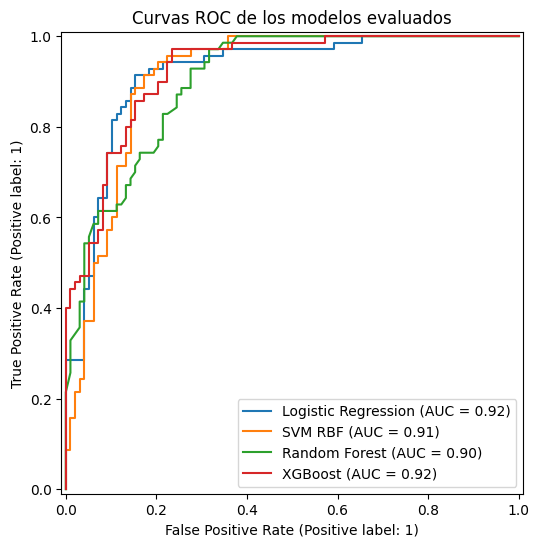

In [ ]:
plt.figure(figsize=(7,6))

for name, model in models.items():
    model.fit(X_train, y_train)
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=plt.gca())

plt.title("Curvas ROC de los modelos evaluados")
plt.show()

In [ ]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cv_results = []

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

for name, model in models.items():
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring)

    cv_results.append({
        "Modelo": name,
        "Accuracy CV": scores["test_accuracy"].mean(),
        "Precision CV": scores["test_precision"].mean(),
        "Recall CV": scores["test_recall"].mean(),
        "F1 CV": scores["test_f1"].mean(),
        "ROC-AUC CV": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,Modelo,Accuracy CV,Precision CV,Recall CV,F1 CV,ROC-AUC CV
0,Logistic Regression,0.867671,0.812094,0.897698,0.851122,0.918210
1,SVM RBF,0.858176,0.794388,0.900794,0.842969,0.906751
2,Random Forest,0.840333,0.798611,0.832698,0.814167,0.904658
3,XGBoost,0.856999,0.807060,0.872381,0.836549,0.919646



El modelo con solo variables clínicas tuvo un rendimiento menor que el modelo basado únicamente en mutaciones. Esto indica que la información genética aporta mayor capacidad predictiva para distinguir LGG de GBM. Sin embargo, el mejor ROC-AUC se obtuvo al combinar variables clínicas y mutacionales, lo que refuerza la importancia de integrar ambos tipos de información.

In [ ]:
# 8. entrenamiento final para interpretabilidad

# Recuperar modelos desde el diccionario
log_model = models["Logistic Regression"]
rf_model = models["Random Forest"]
xgb_model = models["XGBoost"]

# Entrenar modelos con los datos ya preprocesados
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

print("Modelos entrenados correctamente.")
print("Número de variables:", len(feature_names))

Modelos entrenados correctamente.
Número de variables: 25


In [ ]:

# importancia de variables - Random Forest


rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

rf_importance.head(15)

,Feature,Importance
1,Age_at_diagnosis,0.316700
2,IDH1,0.297854
4,ATRX,0.052232
7,CIC,0.046896
5,PTEN,0.042586
19,IDH2,0.029665
3,TP53,0.022254
0,Gender,0.021354
6,EGFR,0.019289
10,NF1,0.016958


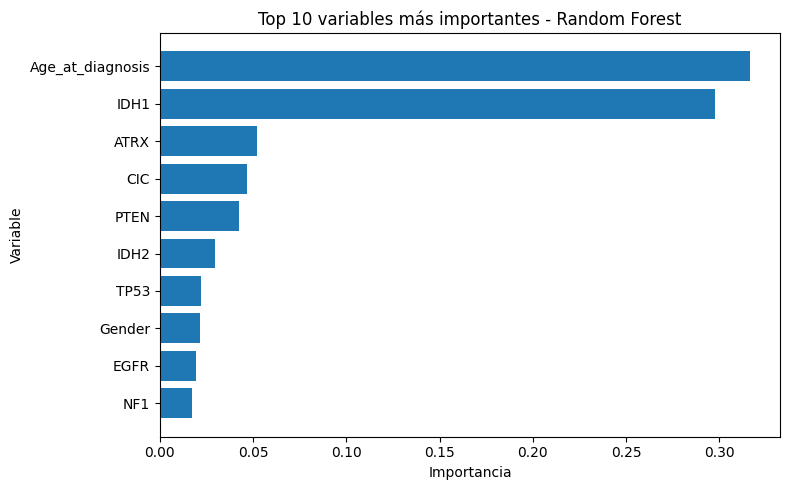

In [ ]:
top_rf = rf_importance.head(10).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(top_rf["Feature"], top_rf["Importance"])
plt.title("Top 10 variables más importantes - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


Random Forest identificó como variables principales a la edad al diagnóstico e `IDH1`, lo que sugiere que tanto la información clínica como la información genética aportan a la clasificación del tumor.

In [ ]:

# importancia de variables - XGBoost


xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

xgb_importance.head(15)

,Feature,Importance
2,IDH1,0.410681
19,IDH2,0.083899
7,CIC,0.074198
5,PTEN,0.037266
10,NF1,0.029235
1,Age_at_diagnosis,0.027333
6,EGFR,0.026078
4,ATRX,0.025642
14,NOTCH1,0.024088
8,MUC16,0.023750


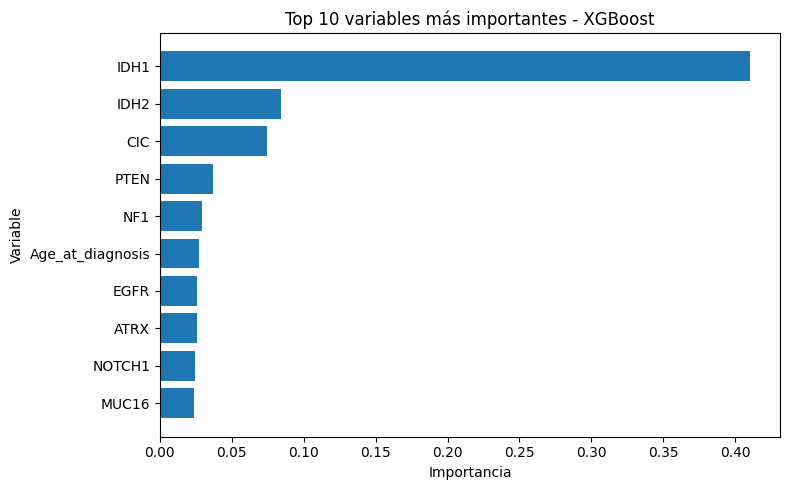

In [ ]:
top_xgb = xgb_importance.head(10).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(top_xgb["Feature"], top_xgb["Importance"])
plt.title("Top 10 variables más importantes - XGBoost")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


Las variables más influyentes en los modelos fueron principalmente mutaciones genéticas y la edad al diagnóstico. En particular, `IDH1` aparece como la variable más importante en XGBoost y también entre las principales en Random Forest. Esto es coherente con el enfoque del proyecto, ya que la clasificación de gliomas depende fuertemente de marcadores moleculares asociados al comportamiento tumoral.

In [ ]:

# Coeficientes - Logistic Regression


logistic_classifier = log_model.named_steps["model"]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logistic_classifier.coef_[0],
    "AbsCoefficient": np.abs(logistic_classifier.coef_[0]),
    "OddsRatio": np.exp(logistic_classifier.coef_[0])
}).sort_values(by="AbsCoefficient", ascending=False)

coef_df.head(15)

,Feature,Coefficient,AbsCoefficient,OddsRatio
2,IDH1,-1.975828,1.975828,0.138646
14,NOTCH1,-1.075852,1.075852,0.341007
3,TP53,0.664947,0.664947,1.944387
19,IDH2,-0.604025,0.604025,0.546607
1,Age_at_diagnosis,0.600514,0.600514,1.823055
23,Race_black or african american,0.506140,0.506140,1.658876
24,Race_white,0.434638,0.434638,1.544404
18,GRIN2A,0.404434,0.404434,1.498454
10,NF1,-0.340313,0.340313,0.711548
22,Race_asian,0.314155,0.314155,1.369102


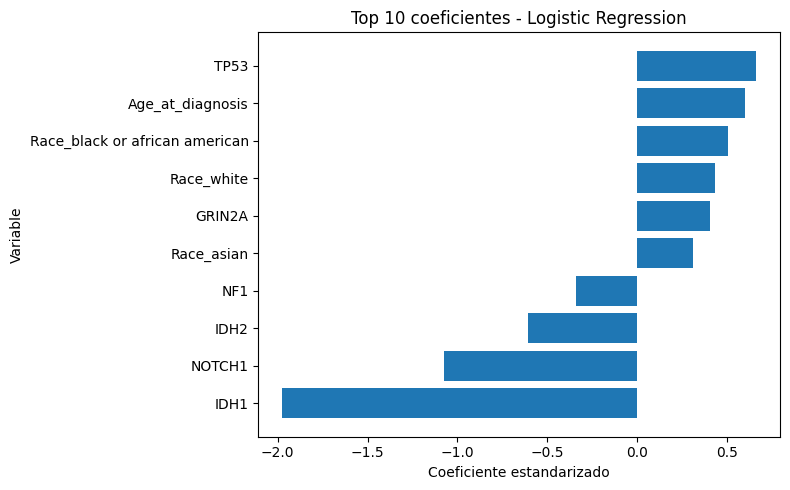

In [ ]:
top_coef = coef_df.head(10).sort_values(by="Coefficient", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(top_coef["Feature"], top_coef["Coefficient"])
plt.title("Top 10 coeficientes - Logistic Regression")
plt.xlabel("Coeficiente estandarizado")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


La regresión logística permitió observar qué variables tienen mayor peso dentro de un modelo interpretable. Aunque su estructura es más simple que XGBoost, sus resultados fueron competitivos, lo que sugiere que una parte importante de la separación entre LGG y GBM puede explicarse mediante relaciones relativamente claras entre variables clínicas y mutacionales.

In [ ]:

# Permutation Importance - XGBoost


from sklearn.inspection import permutation_importance

perm_xgb = permutation_importance(
    xgb_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="roc_auc"
)

perm_xgb_df = pd.DataFrame({
    "Feature": feature_names,
    "MeanDecreaseROC_AUC": perm_xgb.importances_mean,
    "Std": perm_xgb.importances_std
}).sort_values(by="MeanDecreaseROC_AUC", ascending=False)

perm_xgb_df.head(15)

,Feature,MeanDecreaseROC_AUC,Std
2,IDH1,0.314832,0.032389
1,Age_at_diagnosis,0.028836,0.011868
5,PTEN,0.005804,0.004762
19,IDH2,0.003912,0.003585
18,GRIN2A,0.003737,0.002821
0,Gender,0.002881,0.002366
7,CIC,0.002143,0.002395
11,PIK3R1,0.001370,0.002539
10,NF1,0.001361,0.003844
14,NOTCH1,0.001195,0.001732


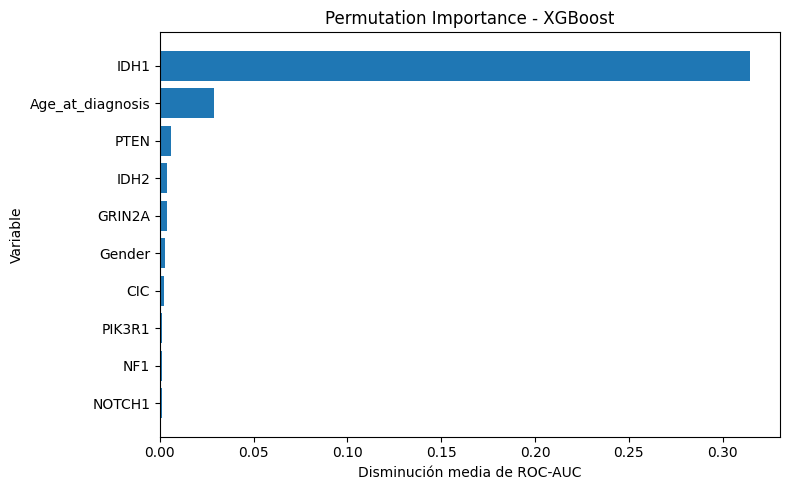

In [ ]:
top_perm = perm_xgb_df.head(10).sort_values(by="MeanDecreaseROC_AUC", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(top_perm["Feature"], top_perm["MeanDecreaseROC_AUC"])
plt.title("Permutation Importance - XGBoost")
plt.xlabel("Disminución media de ROC-AUC")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

In [ ]:

# tabla resumen de variables importantes


top_features_summary = pd.DataFrame({
    "Random Forest": rf_importance["Feature"].head(10).values,
    "XGBoost": xgb_importance["Feature"].head(10).values,
    "Logistic Regression": coef_df["Feature"].head(10).values,
    "Permutation XGBoost": perm_xgb_df["Feature"].head(10).values
})

top_features_summary

,Random Forest,XGBoost,Logistic Regression,Permutation XGBoost
0,Age_at_diagnosis,IDH1,IDH1,IDH1
1,IDH1,IDH2,NOTCH1,Age_at_diagnosis
2,ATRX,CIC,TP53,PTEN
3,CIC,PTEN,IDH2,IDH2
4,PTEN,NF1,Age_at_diagnosis,GRIN2A
5,IDH2,Age_at_diagnosis,Race_black or african american,Gender
6,TP53,EGFR,Race_white,CIC
7,Gender,ATRX,GRIN2A,PIK3R1
8,EGFR,NOTCH1,NF1,NF1
9,NF1,MUC16,Race_asian,NOTCH1


Varianza explicada por PCA: [0.11473505 0.08187887]
Varianza acumulada: 0.1966139243866034


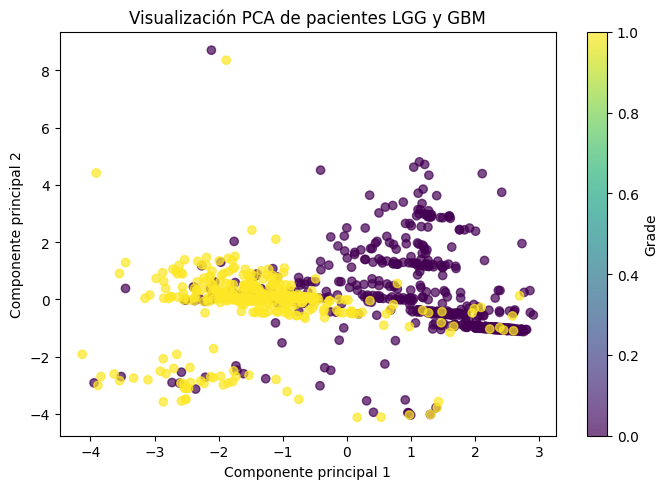

In [ ]:

# Visualizacion con PCA y t-SNE


from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Escalamiento de variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA a 2 componentes
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Grade": y
})

print("Varianza explicada por PCA:", pca.explained_variance_ratio_)
print("Varianza acumulada:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 5))
plt.scatter(pca_df["PC1"], pca_df["PC2"], c=pca_df["Grade"], alpha=0.7)
plt.title("Visualización PCA de pacientes LGG y GBM")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.colorbar(label="Grade")
plt.tight_layout()
plt.show()


PCA permitió visualizar los pacientes en dos dimensiones, pero las dos primeras componentes solo explican cerca del 19.7% de la variabilidad total. Por ello, esta visualización debe interpretarse como una exploración general y no como una representación completa de toda la información clínica y genética.

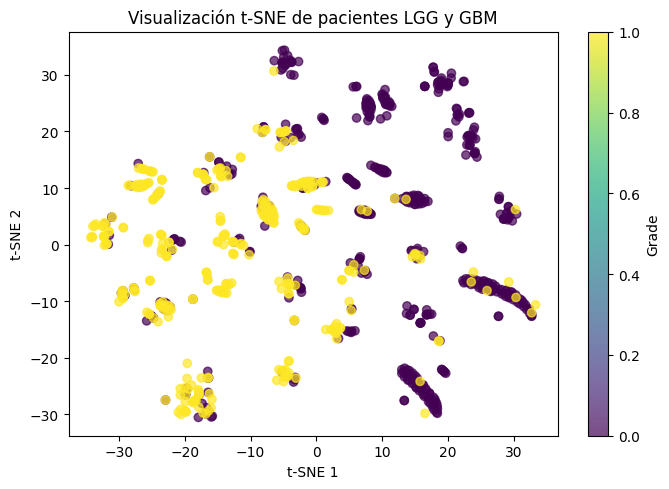

In [ ]:
# t-SNE para visualización no lineal
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame({
    "tSNE1": X_tsne[:, 0],
    "tSNE2": X_tsne[:, 1],
    "Grade": y
})

plt.figure(figsize=(7, 5))
plt.scatter(tsne_df["tSNE1"], tsne_df["tSNE2"], c=tsne_df["Grade"], alpha=0.7)
plt.title("Visualización t-SNE de pacientes LGG y GBM")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(label="Grade")
plt.tight_layout()
plt.show()

  
t-SNE se utilizó como una herramienta visual para explorar posibles agrupamientos no lineales entre pacientes. A diferencia de PCA, esta técnica busca preservar vecindades locales, por lo que ayuda a observar si existen grupos de pacientes con perfiles similares, aunque no debe usarse como evidencia predictiva principal.

In [ ]:

# Clustering exploratorio con K-Means


from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

ari = adjusted_rand_score(y, clusters)
nmi = normalized_mutual_info_score(y, clusters)

print("Adjusted Rand Index:", ari)
print("Normalized Mutual Information:", nmi)

cluster_df = pd.DataFrame({
    "Cluster": clusters,
    "Grade": y
})

pd.crosstab(cluster_df["Cluster"], cluster_df["Grade"])

Adjusted Rand Index: 0.5023542259820698
Normalized Mutual Information: 0.42510774715173405


Grade,0,1
Cluster,,
0,94,324
1,393,28


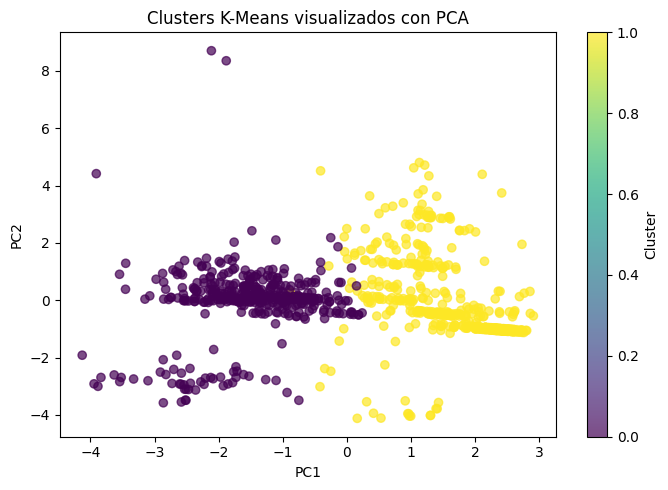

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, alpha=0.7)
plt.title("Clusters K-Means visualizados con PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


K-Means mostró una separación parcial entre los perfiles de pacientes. Aunque el clustering no utiliza las etiquetas reales, los grupos obtenidos se relacionan de manera moderada con LGG y GBM. Esto sugiere que los perfiles clínico-mutacionales contienen una estructura interna compatible con la clasificación tumoral, aunque no suficiente para reemplazar a los modelos supervisados.

In [ ]:

# Comparacion por grupos de variables


clinical_features = [col for col in X.columns if col.startswith("Race_") or col in ["Gender", "Age_at_diagnosis"]]
mutation_features = [col for col in X.columns if col not in clinical_features]

feature_groups = {
    "Solo clínicas": clinical_features,
    "Solo mutaciones": mutation_features,
    "Clínicas + mutaciones": X.columns.tolist()
}
group_results = []
for group_name, cols in feature_groups.items():
    X_group = X[cols]
    X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
        X_group,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
    model = XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )

    model.fit(X_train_g, y_train_g)

    y_pred_g = model.predict(X_test_g)
    y_proba_g = model.predict_proba(X_test_g)[:, 1]

    group_results.append({
        "Grupo de variables": group_name,
        "Número de variables": len(cols),
        "Accuracy": accuracy_score(y_test_g, y_pred_g),
        "Precision": precision_score(y_test_g, y_pred_g),
        "Recall": recall_score(y_test_g, y_pred_g),
        "F1-score": f1_score(y_test_g, y_pred_g),
        "ROC-AUC": roc_auc_score(y_test_g, y_proba_g)
    })

group_results_df = pd.DataFrame(group_results)
group_results_df

,Grupo de variables,Número de variables,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Solo clínicas,5,0.732143,0.727273,0.571429,0.640000,0.828644
1,Solo mutaciones,20,0.851190,0.784810,0.885714,0.832215,0.906050
2,Clínicas + mutaciones,25,0.851190,0.800000,0.857143,0.827586,0.924344


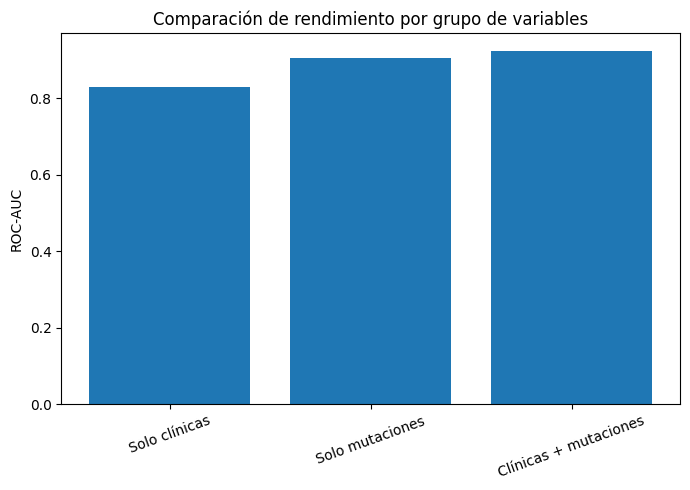

In [ ]:
plt.figure(figsize=(7, 5))
plt.bar(group_results_df["Grupo de variables"], group_results_df["ROC-AUC"])
plt.title("Comparación de rendimiento por grupo de variables")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


El modelo con solo variables clínicas tuvo un rendimiento menor que el modelo basado únicamente en mutaciones. Esto indica que la información genética aporta mayor capacidad predictiva para distinguir LGG de GBM. Sin embargo, el mejor ROC-AUC se obtuvo al combinar variables clínicas y mutacionales, lo que refuerza la importancia de integrar ambos tipos de información.

***

## Análisis de los resultados más relevantes

**1. Desempeño general de los modelos (test set, 20%):**

| Modelo | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Regresión Logística | 0.857 | 0.811 | 0.857 | 0.833 | 0.918 |
| SVM (RBF) | 0.863 | 0.805 | 0.886 | 0.844 | 0.910 |
| Random Forest | 0.792 | 0.761 | 0.729 | 0.745 | 0.902 |
| **XGBoost** | 0.851 | 0.800 | 0.857 | 0.828 | **0.924** |

Los cuatro modelos superan el 0.90 de ROC-AUC, lo cual indica que el problema es **razonablemente separable** con las variables disponibles. **XGBoost** obtiene el mejor ROC-AUC (0.924) y la matriz de confusión muestra un buen balance entre falsos positivos (15) y falsos negativos (10) sobre 168 pacientes de prueba. **Random Forest** es consistentemente el modelo más débil, probablemente porque sin ajuste de hiperparámetros tiende a ser menos sensible a patrones de interacción entre mutaciones específicas.

**2. Validación cruzada (Stratified 10-Fold):**
Los resultados de CV son muy similares a los del test set (diferencias menores a 2 puntos porcentuales en todas las métricas), lo que sugiere que **no hay overfitting relevante** y que la partición train/test original fue representativa. La Regresión Logística y XGBoost lideran en ROC-AUC promedio (0.918 y 0.920 respectivamente), reforzando que un modelo simple y uno complejo llegan a un techo de desempeño similar con este dataset.

**3. Importancia de variables — consenso entre métodos:**
Al comparar Random Forest, XGBoost, coeficientes de Regresión Logística y Permutation Importance, un grupo pequeño de variables aparece de forma consistente en el top 5 de **los cuatro métodos**: **IDH1, IDH2, ATRX, CIC, PTEN** y **Age_at_diagnosis** esto es clinicamente coherente por que la mutación de **IDH1/IDH2** es, en la literatura oncológica el marcador molecular más usado para distinguir LGG de GBM, y la edad al diagnóstico es un factor pronóstico clásico. La coincidencia entre modelos de naturaleza tan distinta (lineal, árboles, boosting, permutación) da **robustez** a estos hallazgos, más allá de las particularidades de un solo algoritmo.

**4. Variables clínicas vs. mutacionales vs. combinadas:**

| Grupo de variables | N° variables | ROC-AUC |
|---|---|---|
| Solo clínicas | 5 | 0.829 |
| Solo mutaciones | 20 | 0.906 |
| **Clínicas + mutaciones** | 25 | **0.924** |

Las variables **puramente clínicas ya logran un ROC-AUC de 0.83**, mayor de lo esperable para datos tan simples, pero muy por debajo de usar solo mutaciones (0.906). La combinación de ambos tipos de variables produce el mejor resultado global (0.924), confirmando que el perfil genómico aporta la mayor parte del poder predictivo, pero que los datos clínicos (en especial la edad) añaden información complementaria no redundante.

**5. Evidencia no supervisada (PCA, t-SNE, K-Means):**
La proyección en 2D mediante PCA y t-SNE muestra una **separación visual parcial** entre las clases LGG y GBM sin usar la etiqueta, y el clustering con K-Means (k=2) recupera una estructura de grupos que se alinea razonablemente con las clases reales. Esto **valida de forma independiente** que la señal detectada por los modelos supervisados no es artificial: existe una estructura genuina en los datos que separa ambos grados tumorales incluso antes de aplicar cualquier algoritmo de clasificación.

**Conclusión parcial:** el pipeline logra un desempeño alto y estable (ROC-AUC ≈ 0.92) con modelos relativamente simples, y la interpretabilidad confirma que los genes seleccionados como más importantes coinciden con marcadores moleculares ya validados clínicamente (IDH1/IDH2), lo que da soporte tanto estadístico como biológico a los resultados obtenidos.

---
